# 🛍️ E-Commerce Customer Value & Churn
### RFM segmentation on the *Online Retail II* dataset

**Goal** – segment online shoppers by *how recently*, *how often* and *how much* they buy,
so marketing spend and retention effort go where they matter most.

| Section | What you'll find |
|---|---|
| 1. Setup | Libraries, colours and tunable thresholds |
| 2. Load data | Download + cache the raw transactions |
| 3. Data quality | What is dirty, what we drop, and why |
| 4. Business overview | Revenue trend and top markets |
| 5. RFM metrics | Recency, Frequency, Monetary per customer |
| 6. Segmentation | Champions, Loyal, At-Risk, Hibernating … |
| 7. Pareto analysis | Do the top 20% of customers drive 80% of revenue? |
| 8. At-Risk VIPs | Exportable CSV for targeted campaigns |
| 9. Re-engagement plan | Incentives by days since last purchase |
| 10. Key takeaways | The short version |

## 1 · Setup
Everything tunable lives in this one cell – the notebook equivalent of the dashboard sliders.
Change a value, re-run the cells below, and every chart and table updates.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

# ── Paths ──────────────────────────────────────────────────────────
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
RAW_XLSX = DATA_DIR / "online_retail_II.xlsx"
CACHE_CSV = DATA_DIR / "online_retail_ii.csv"
DATASET_URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"

# ── Tunable thresholds ("the sliders") ─────────────────────────────
N_BINS = 5                 # RFM scores run from 1 (worst) to N_BINS (best)
VIP_MONETARY_PERCENTILE = 0.80   # "VIP" = spends more than this share of customers
PARETO_TOP_SHARE = 0.20          # the "top 20%" in the 80/20 rule

# ── Colours (one fixed colour per segment, used in every chart) ────
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
)
GREY, INK, MUTED = "#c9c8c3", "#0b0b0b", "#52514e"

SEGMENT_COLORS = {
    "Champions": BLUE,
    "Loyal": AQUA,
    "New / Promising": YELLOW,
    "Potential Loyalists": MAGENTA,
    "At-Risk": ORANGE,
    "Hibernating": GREY,
}

# ── Plot style ─────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GREY,
    "axes.labelcolor": MUTED,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#ececea",
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": INK,
    "font.size": 10,
})
pd.options.display.float_format = "{:,.2f}".format
OUTPUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

In [2]:
def money(x, _=None):
    """Format a number as compact pounds, e.g. 1_250_000 -> £1.25M."""
    if abs(x) >= 1e6:
        return f"£{x / 1e6:.1f}M"
    if abs(x) >= 1e3:
        return f"£{x / 1e3:.0f}K"
    return f"£{x:.0f}"


def label_bars(ax, fmt, pad=3):
    """Write each bar's value at its tip."""
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt(v) for v in container.datavalues],
                     padding=pad, color=INK, fontsize=9)

## 2 · Load the data
The *Online Retail II* dataset (UCI / Kaggle) holds every transaction of a UK-based online gift
retailer between **Dec 2009 and Dec 2011**. It ships as an Excel file with one sheet per year.

The first run downloads and converts it to CSV (about a minute); later runs load the CSV instantly.

In [3]:
def download_raw_data():
    """Fetch and unzip the Excel file from UCI if we don't have it yet."""
    zip_path = DATA_DIR / "online_retail_ii.zip"
    print("Downloading dataset …")
    urlretrieve(DATASET_URL, zip_path)
    with ZipFile(zip_path) as archive:
        archive.extractall(DATA_DIR)


def load_transactions():
    """Return all transactions as one DataFrame, using a CSV cache when possible."""
    if CACHE_CSV.exists():
        return pd.read_csv(CACHE_CSV, parse_dates=["InvoiceDate"], dtype={"Customer ID": "Int64"})

    if not RAW_XLSX.exists():
        download_raw_data()

    sheets = pd.read_excel(RAW_XLSX, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
    frame = pd.concat(sheets.values(), ignore_index=True)
    frame["Customer ID"] = frame["Customer ID"].astype("Int64")
    frame.to_csv(CACHE_CSV, index=False)
    return frame


raw = load_transactions()
print(f"{len(raw):,} rows × {raw.shape[1]} columns")
raw.head()

1,067,371 rows × 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


## 3 · Data quality
Transactional data is rarely analysis-ready. Before computing anything, let's see what's wrong.

In [4]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean() * 100,
})
quality

,dtype,missing,missing_%
Invoice,object,0,0.00
StockCode,object,0,0.00
Description,object,4382,0.41
Quantity,int64,0,0.00
InvoiceDate,datetime64[ns],0,0.00
Price,float64,0,0.00
Customer ID,Int64,243007,22.77
Country,object,0,0.00


Three things stand out:

* **`Customer ID` is missing on ~23% of rows** – guest checkouts. Without an ID we cannot build a customer profile.
* **Invoices starting with `C`** are cancellations / returns, and carry negative quantities.
* Some rows have a **zero or negative price** (manual stock adjustments) and some **non-product stock codes**
  (postage, bank charges, manual entries).

In [5]:
def apply_cleaning_rules(df):
    """Apply each cleaning rule in turn; return the clean frame and a log of rows removed."""
    rules = {
        "Cancellations (invoice starts with 'C')": ~df["Invoice"].str.startswith("C"),
        "Non-positive quantity":                   df["Quantity"] > 0,
        "Non-positive price":                      df["Price"] > 0,
        "Missing Customer ID":                     df["Customer ID"].notna(),
        "Non-product codes (POST, BANK CHARGES …)": df["StockCode"].str.match(r"^\d{5}"),
    }
    log, current = [], df
    for name, keep in rules.items():
        keep = keep.loc[current.index]
        log.append({"rule": name, "rows_removed": int((~keep).sum())})
        current = current[keep]
    return current.copy(), pd.DataFrame(log)


clean, cleaning_log = apply_cleaning_rules(raw)
cleaning_log

,rule,rows_removed
0,Cancellations (invoice starts with 'C'),19494
1,Non-positive quantity,3457
2,Non-positive price,2750
3,Missing Customer ID,236121
4,"Non-product codes (POST, BANK CHARGES …)",2917


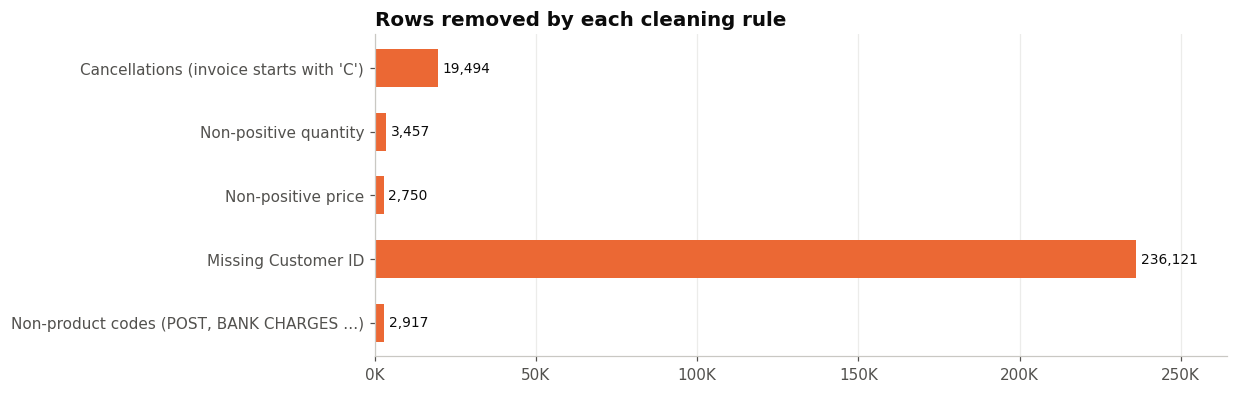

Kept 802,632 of 1,067,371 rows (75%).


In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(cleaning_log["rule"][::-1], cleaning_log["rows_removed"][::-1], color=ORANGE, height=0.6)
label_bars(ax, lambda v: f"{v:,.0f}")
ax.set_title("Rows removed by each cleaning rule")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:.0f}K"))
ax.grid(axis="y", visible=False)
ax.margins(x=0.12)
plt.show()

kept = len(clean) / len(raw)
print(f"Kept {len(clean):,} of {len(raw):,} rows ({kept:.0%}).")

In [8]:
clean["Revenue"] = clean["Quantity"] * clean["Price"]
clean["Customer ID"] = clean["Customer ID"].astype(int)

summary = pd.Series({
    "Customers":         clean["Customer ID"].nunique(),
    "Invoices":          clean["Invoice"].nunique(),
    "Products":          clean["StockCode"].nunique(),
    "Countries":         clean["Country"].nunique(),
    "Total revenue (£)": clean["Revenue"].sum(),
    "First purchase":    clean["InvoiceDate"].min().date(),
    "Last purchase":     clean["InvoiceDate"].max().date(),
})
summary.to_frame("clean dataset")

,clean dataset
Customers,5852
Invoices,36594
Products,4619
Countries,41
Total revenue (£),"17,434,449.98"
First purchase,2009-12-01
Last purchase,2011-12-09


## 4 · Business overview
A quick look at the shape of the business before we segment it.

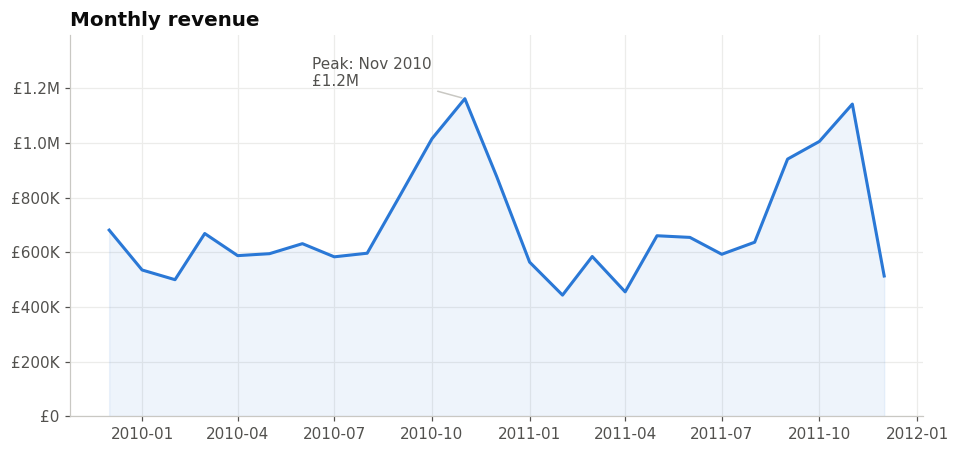

In [9]:
monthly_revenue = clean.set_index("InvoiceDate")["Revenue"].resample("MS").sum()

fig, ax = plt.subplots()
ax.plot(monthly_revenue.index, monthly_revenue.values, color=BLUE, linewidth=2)
ax.fill_between(monthly_revenue.index, monthly_revenue.values, color=BLUE, alpha=0.08)
ax.set_title("Monthly revenue")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_ylim(0, monthly_revenue.max() * 1.2)

peak = monthly_revenue.idxmax()
ax.annotate(f"Peak: {peak:%b %Y}\n{money(monthly_revenue.max())}",
            xy=(peak, monthly_revenue.max()), xytext=(-100, 8), textcoords="offset points",
            color=MUTED, arrowprops=dict(arrowstyle="-", color=GREY))
plt.show()

Revenue builds towards a strong **Q4 peak** each year – the gift-buying season. (Dec 2011 is partial – the data ends on 9 Dec.)

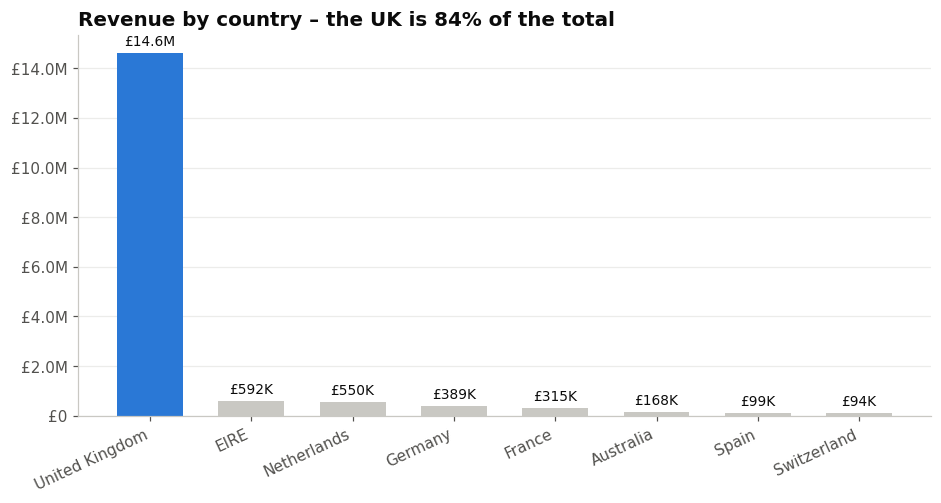

In [10]:
country_revenue = clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
top_countries = country_revenue.head(8)
uk_share = country_revenue["United Kingdom"] / country_revenue.sum()

fig, ax = plt.subplots()
colors = [BLUE if country == "United Kingdom" else GREY for country in top_countries.index]
ax.bar(top_countries.index, top_countries.values, color=colors, width=0.65)
label_bars(ax, money)
ax.set_title(f"Revenue by country – the UK is {uk_share:.0%} of the total")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.grid(axis="x", visible=False)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.show()

## 5 · RFM metrics
RFM describes each customer with three numbers:

| Metric | Question | Calculation |
|---|---|---|
| **R**ecency | How recently did they buy? | Days between their last purchase and the snapshot date |
| **F**requency | How often do they buy? | Number of distinct invoices |
| **M**onetary | How much do they spend? | Total revenue |

The **snapshot date** is one day after the final transaction, so the most recent buyers have a recency of 1 day.

In [11]:
snapshot_date = clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = clean.groupby("Customer ID").agg(
    last_purchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)
rfm["Recency"] = (snapshot_date - rfm["last_purchase"].dt.normalize()).dt.days

print(f"Snapshot date: {snapshot_date.date()}  |  Customers: {len(rfm):,}")
rfm[["Recency", "Frequency", "Monetary"]].describe().T

Snapshot date: 2011-12-10  |  Customers: 5,852


,count,mean,std,min,25%,50%,75%,max
Recency,"5,852.00",200.73,208.52,1.00,26.00,96.00,380.00,739.00
Frequency,"5,852.00",6.25,12.75,1.00,1.00,3.00,7.00,373.00
Monetary,"5,852.00","2,979.23","14,604.97",2.95,344.98,880.38,"2,289.34","608,821.65"


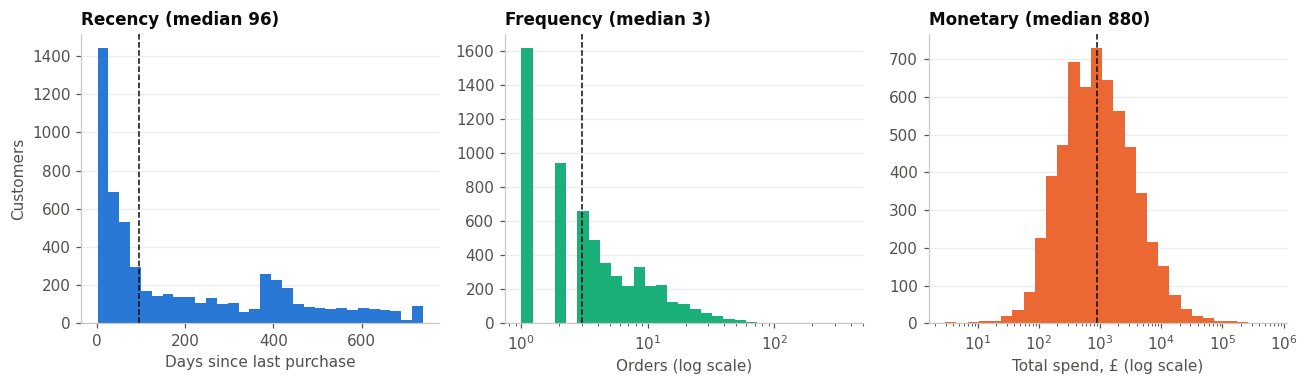

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
panels = [
    ("Recency",   "Days since last purchase", BLUE,   rfm["Recency"]),
    ("Frequency", "Orders (log scale)",       AQUA,   rfm["Frequency"]),
    ("Monetary",  "Total spend, £ (log scale)", ORANGE, rfm["Monetary"]),
]
for ax, (title, xlabel, color, values) in zip(axes, panels):
    if title == "Recency":
        ax.hist(values, bins=30, color=color)
    else:
        ax.hist(values, bins=np.logspace(np.log10(values.min()), np.log10(values.max()), 30), color=color)
        ax.set_xscale("log")
    ax.axvline(values.median(), color=INK, linestyle="--", linewidth=1)
    ax.set_title(f"{title} (median {values.median():,.0f})", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Customers")
fig.tight_layout()
plt.show()

Frequency and Monetary are **heavily right-skewed** – a few customers buy a lot, most buy a little.
That is why we score by **quintiles** (ranks) instead of raw values: it keeps outliers from swamping the scale.

## 6 · Customer segmentation
Each metric is converted into a score from **1 (worst) to 5 (best)**. Then simple rules on the
**Recency** and **Frequency** scores place every customer into a named segment.

| Segment | Rule | In plain words |
|---|---|---|
| **Champions** | R ≥ 4 and F ≥ 4 | Bought recently, buy often |
| **Loyal** | R ≥ 3 and F ≥ 3 | Solid, regular customers |
| **New / Promising** | R ≥ 4 | Recent, but few orders so far |
| **Potential Loyalists** | R = 3 | Mid-recency, could be nurtured |
| **At-Risk** | R ≤ 2 and F ≥ 3 | Used to buy often, gone quiet |
| **Hibernating** | R ≤ 2 and F ≤ 2 | Low activity and long gone |

*(Rules are checked top to bottom; the first match wins.)*

In [13]:
def score_quantiles(series, n_bins=N_BINS, higher_is_better=True):
    """Score a metric 1..n_bins using quantile bins (ranked first, to break ties)."""
    labels = range(1, n_bins + 1) if higher_is_better else range(n_bins, 0, -1)
    return pd.qcut(series.rank(method="first"), q=n_bins, labels=labels).astype(int)


def assign_segment(r, f):
    """Map Recency / Frequency scores to a segment name (first matching rule wins)."""
    top = N_BINS - 1          # "high" = top two bins
    mid = N_BINS - 2
    if r >= top and f >= top:
        return "Champions"
    if r >= mid and f >= mid:
        return "Loyal"
    if r >= top:
        return "New / Promising"
    if r == mid:
        return "Potential Loyalists"
    if f >= mid:
        return "At-Risk"
    return "Hibernating"


rfm["R_score"] = score_quantiles(rfm["Recency"], higher_is_better=False)   # low recency = good
rfm["F_score"] = score_quantiles(rfm["Frequency"])
rfm["M_score"] = score_quantiles(rfm["Monetary"])
rfm["Segment"] = [assign_segment(r, f) for r, f in zip(rfm["R_score"], rfm["F_score"])]

rfm[["Recency", "Frequency", "Monetary", "R_score", "F_score", "M_score", "Segment"]].head()

,Recency,Frequency,Monetary,R_score,F_score,M_score,Segment
Customer ID,,,,,,,
12346,326,3,"77,352.96",2,3,5,At-Risk
12347,3,8,"5,633.32",5,4,5,Champions
12348,76,5,"1,658.40",3,4,4,Loyal
12349,19,3,"3,678.69",5,3,5,Loyal
12350,311,1,294.40,2,1,2,Hibernating


In [14]:
segment_order = list(SEGMENT_COLORS)

segment_summary = (
    rfm.groupby("Segment")
    .agg(customers=("Monetary", "size"),
         revenue=("Monetary", "sum"),
         avg_recency_days=("Recency", "mean"),
         avg_orders=("Frequency", "mean"),
         avg_spend=("Monetary", "mean"))
    .reindex(segment_order)
)
segment_summary["customer_share"] = segment_summary["customers"] / segment_summary["customers"].sum()
segment_summary["revenue_share"] = segment_summary["revenue"] / segment_summary["revenue"].sum()
segment_summary

,customers,revenue,avg_recency_days,avg_orders,avg_spend,customer_share,revenue_share
Segment,,,,,,,
Champions,1463,"12,029,862.49",20.53,15.60,"8,222.74",0.25,0.69
Loyal,1218,"2,508,280.16",78.34,5.39,"2,059.34",0.21,0.14
New / Promising,447,"414,134.43",28.40,1.47,926.48,0.08,0.02
Potential Loyalists,383,"206,717.10",105.89,1.36,539.73,0.07,0.01
At-Risk,830,"1,642,106.96",368.12,4.99,"1,978.44",0.14,0.09
Hibernating,1511,"633,348.84",456.94,1.25,419.16,0.26,0.04


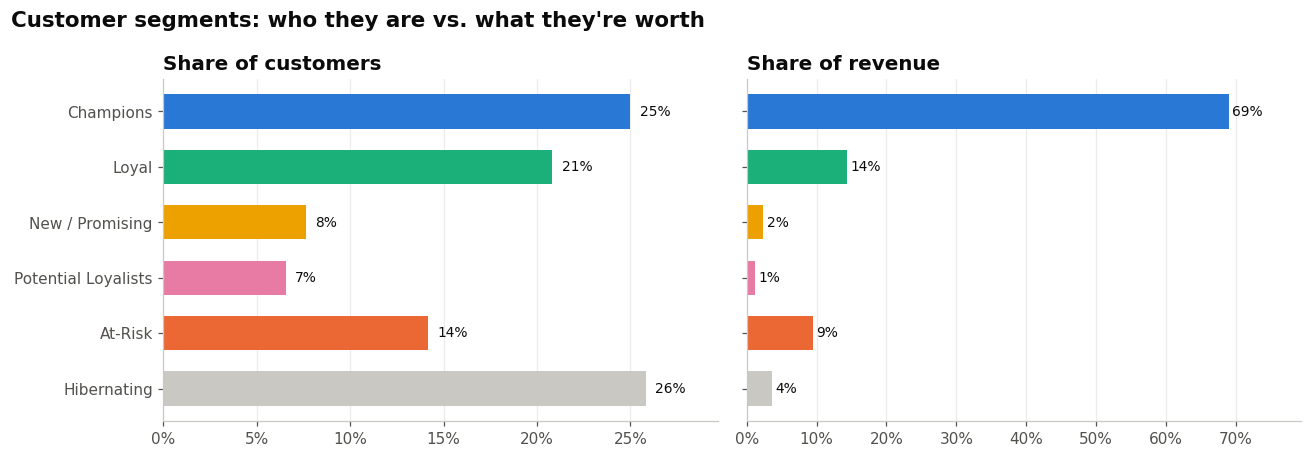

In [15]:
fig, (ax_customers, ax_revenue) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
colors = [SEGMENT_COLORS[s] for s in segment_summary.index]
ypos = np.arange(len(segment_summary))[::-1]

for ax, column, title in [
    (ax_customers, "customer_share", "Share of customers"),
    (ax_revenue,   "revenue_share",  "Share of revenue"),
]:
    ax.barh(ypos, segment_summary[column], color=colors, height=0.62)
    for y, value in zip(ypos, segment_summary[column]):
        ax.text(value + 0.005, y, f"{value:.0%}", va="center", fontsize=9)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.15)

ax_customers.set_yticks(ypos, segment_summary.index)
fig.suptitle("Customer segments: who they are vs. what they're worth",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
plt.show()

Compare the two panels: **Champions are a minority of customers but the majority of revenue**, while
Hibernating customers are numerous yet contribute little. This is the case for treating segments differently.

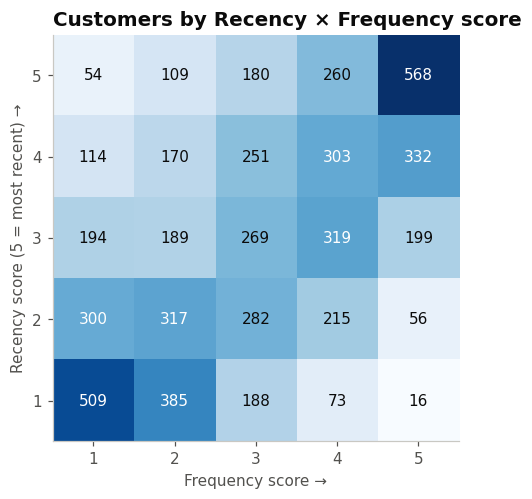

In [16]:
heatmap = rfm.pivot_table(index="R_score", columns="F_score", values="Monetary", aggfunc="count").fillna(0)
heatmap = heatmap.sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
image = ax.imshow(heatmap.values, cmap="Blues")
ax.set_xticks(range(len(heatmap.columns)), heatmap.columns)
ax.set_yticks(range(len(heatmap.index)), heatmap.index)
ax.set_xlabel("Frequency score →")
ax.set_ylabel("Recency score (5 = most recent) →")
ax.set_title("Customers by Recency × Frequency score")
ax.grid(False)

threshold = heatmap.values.max() / 2
for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        value = int(heatmap.values[i, j])
        ax.text(j, i, f"{value:,}", ha="center", va="center",
                color="white" if value > threshold else INK, fontsize=10)
plt.show()

## 7 · Pareto analysis – the 80/20 rule
**Business question:** do the top 20% of customers really generate 80% of revenue?
We rank customers by spend and accumulate their share of total revenue.

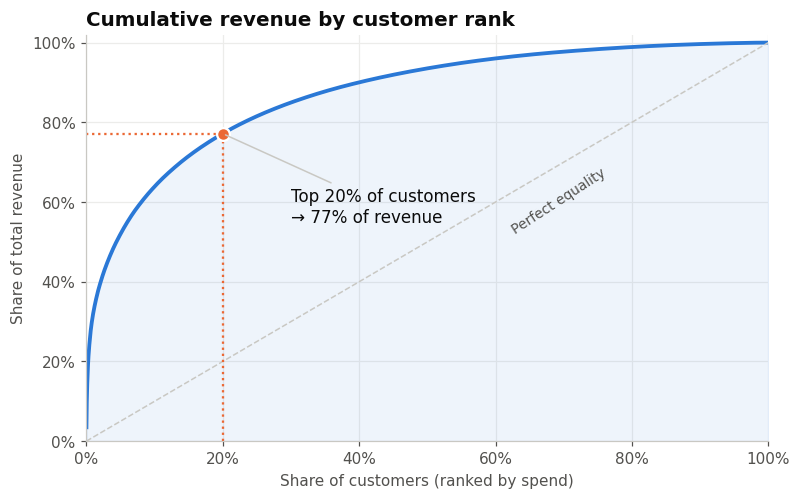

1,170 customers (20%) generate 77.2% of £17,434,450 revenue.


In [17]:
ranked = rfm["Monetary"].sort_values(ascending=False).reset_index(drop=True)
cumulative_revenue = ranked.cumsum() / ranked.sum()
cumulative_customers = (np.arange(len(ranked)) + 1) / len(ranked)

top_n = int(len(ranked) * PARETO_TOP_SHARE)
top_revenue_share = cumulative_revenue.iloc[top_n - 1]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(cumulative_customers, cumulative_revenue, color=BLUE, linewidth=2.5)
ax.fill_between(cumulative_customers, cumulative_revenue, color=BLUE, alpha=0.08)
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)      # perfect equality
ax.plot([PARETO_TOP_SHARE] * 2, [0, top_revenue_share], color=ORANGE, linestyle=":")
ax.plot([0, PARETO_TOP_SHARE], [top_revenue_share] * 2, color=ORANGE, linestyle=":")
ax.scatter([PARETO_TOP_SHARE], [top_revenue_share], color=ORANGE, s=70, zorder=3,
           edgecolor="white", linewidth=1.5)
ax.annotate(f"Top {PARETO_TOP_SHARE:.0%} of customers\n→ {top_revenue_share:.0%} of revenue",
            xy=(PARETO_TOP_SHARE, top_revenue_share), xytext=(0.30, 0.55),
            fontsize=11, arrowprops=dict(arrowstyle="-", color=GREY))
ax.text(0.62, 0.52, "Perfect equality", color=MUTED, rotation=33, fontsize=9)

ax.set_title("Cumulative revenue by customer rank")
ax.set_xlabel("Share of customers (ranked by spend)")
ax.set_ylabel("Share of total revenue")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
plt.show()

print(f"{top_n:,} customers ({PARETO_TOP_SHARE:.0%}) generate {top_revenue_share:.1%} of £{ranked.sum():,.0f} revenue.")

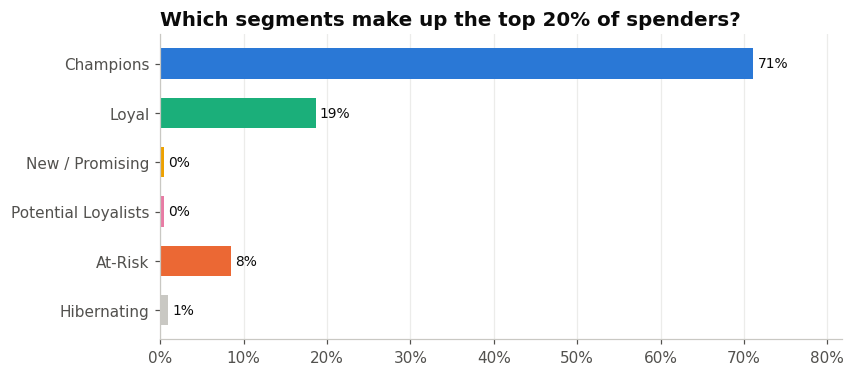

In [18]:
rfm["is_top_20"] = rfm["Monetary"].rank(ascending=False, method="first") <= top_n

top_by_segment = (
    rfm[rfm["is_top_20"]]["Segment"].value_counts(normalize=True).reindex(segment_order).fillna(0)
)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(top_by_segment.index[::-1], top_by_segment.values[::-1],
        color=[SEGMENT_COLORS[s] for s in top_by_segment.index[::-1]], height=0.62)
for y, value in enumerate(top_by_segment.values[::-1]):
    ax.text(value + 0.005, y, f"{value:.0%}", va="center", fontsize=9)
ax.set_title("Which segments make up the top 20% of spenders?")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.margins(x=0.15)
plt.show()

Not every big spender is safe: any top-20% customers sitting in **At-Risk** are high-value relationships
slipping away. That's the group the next section targets.

## 8 · At-Risk VIPs
**At-Risk VIP** = a customer in the **At-Risk** segment whose total spend is above the
`VIP_MONETARY_PERCENTILE` of all customers. They used to buy often, spent a lot, and have gone quiet –
the best candidates for a personal win-back campaign.

In [19]:
vip_spend_cutoff = rfm["Monetary"].quantile(VIP_MONETARY_PERCENTILE)
is_at_risk_vip = (rfm["Segment"] == "At-Risk") & (rfm["Monetary"] >= vip_spend_cutoff)

at_risk_vips = (
    rfm[is_at_risk_vip]
    .sort_values("Monetary", ascending=False)
    .reset_index()
    [["Customer ID", "Recency", "Frequency", "Monetary", "last_purchase"]]
    .rename(columns={"Recency": "days_since_last_purchase", "last_purchase": "last_purchase_date"})
)
at_risk_vips["last_purchase_date"] = at_risk_vips["last_purchase_date"].dt.date

print(f"VIP spend cut-off: £{vip_spend_cutoff:,.0f}")
print(f"{len(at_risk_vips):,} At-Risk VIPs holding £{at_risk_vips['Monetary'].sum():,.0f} of lifetime revenue")
at_risk_vips.head(10)

VIP spend cut-off: £2,955
99 At-Risk VIPs holding £868,573 of lifetime revenue


,Customer ID,days_since_last_purchase,Frequency,Monetary,last_purchase_date
0,12346,326,3,"77,352.96",2011-01-18
1,16754,373,29,"67,502.47",2010-12-02
2,17850,373,155,"56,600.08",2010-12-02
3,13093,276,55,"54,943.65",2011-03-09
4,15749,236,3,"44,534.30",2011-04-18
5,13902,633,5,"34,023.26",2010-03-17
6,12482,577,27,"21,941.72",2010-05-12
7,15808,307,21,"18,409.93",2011-02-06
8,13564,355,36,"16,630.80",2010-12-20
9,17448,530,41,"14,481.97",2010-06-28


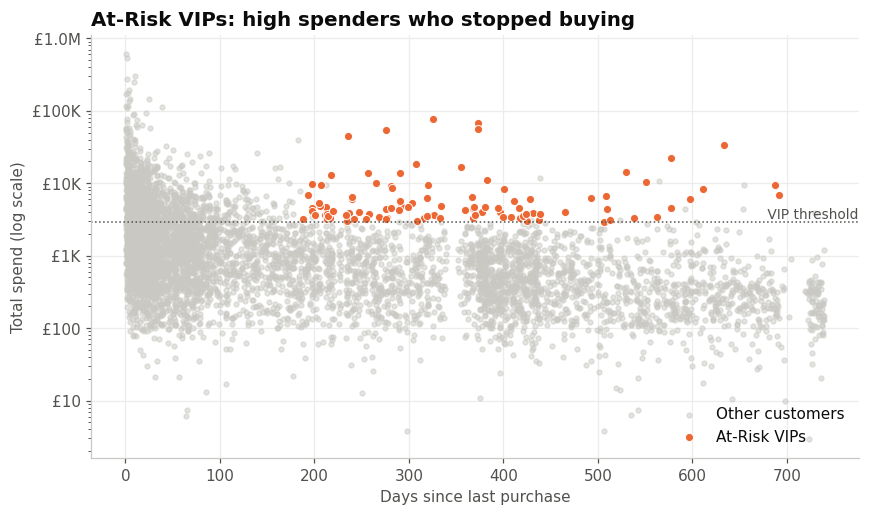

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
others = rfm[~is_at_risk_vip]
ax.scatter(others["Recency"], others["Monetary"], s=10, color=GREY, alpha=0.5, label="Other customers")
ax.scatter(rfm.loc[is_at_risk_vip, "Recency"], rfm.loc[is_at_risk_vip, "Monetary"],
           s=28, color=ORANGE, edgecolor="white", linewidth=0.6, label="At-Risk VIPs")
ax.set_yscale("log")
ax.set_title("At-Risk VIPs: high spenders who stopped buying")
ax.set_xlabel("Days since last purchase")
ax.set_ylabel("Total spend (log scale)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.axhline(vip_spend_cutoff, color=MUTED, linestyle=":", linewidth=1)
ax.text(ax.get_xlim()[1], vip_spend_cutoff, " VIP threshold", va="bottom", ha="right", color=MUTED, fontsize=9)
ax.legend(frameon=False, loc="lower right")
plt.show()

In [21]:
export_path = OUTPUT_DIR / "at_risk_vips.csv"
at_risk_vips.to_csv(export_path, index=False)
print(f"Saved {len(at_risk_vips):,} customers → {export_path}")

Saved 99 customers → outputs/at_risk_vips.csv


## 9 · Re-engagement incentives
Not every lapsed customer needs the same nudge. The longer someone has been away, the stronger the
incentive has to be – but we don't want to give discounts to people who'd come back anyway.

| Days since last purchase | Stage | Suggested incentive |
|---|---|---|
| 0 – 90 | Active | No incentive – protect margin |
| 91 – 180 | Cooling | Friendly reminder + free shipping |
| 181 – 365 | Churn risk | 10% discount on next order |
| 366 – 540 | Likely churned | 15% discount + personalised product picks |
| 540 + | Lost | Final "we miss you" survey + 20% win-back offer |

In [22]:
INCENTIVE_STAGES = pd.DataFrame(
    [
        (0,   "1 · Active",         "No incentive – protect margin"),
        (91,  "2 · Cooling",        "Reminder email + free shipping"),
        (181, "3 · Churn risk",     "10% discount on next order"),
        (366, "4 · Likely churned", "15% discount + personalised picks"),
        (541, "5 · Lost",           "Win-back survey + 20% offer"),
    ],
    columns=["min_days", "stage", "incentive"],
)

rfm["Stage"] = pd.cut(
    rfm["Recency"],
    bins=list(INCENTIVE_STAGES["min_days"]) + [np.inf],
    labels=INCENTIVE_STAGES["stage"],
    right=False,
)

stage_summary = (
    rfm.groupby("Stage", observed=True)
    .agg(customers=("Monetary", "size"), lifetime_revenue=("Monetary", "sum"))
    .join(INCENTIVE_STAGES.set_index("stage")["incentive"])
)
stage_summary

,customers,lifetime_revenue,incentive
Stage,,,
1 · Active,2885,"14,054,858.08",No incentive – protect margin
2 · Cooling,586,"1,025,184.52",Reminder email + free shipping
3 · Churn risk,790,"1,096,262.15",10% discount on next order
4 · Likely churned,1027,"910,092.47",15% discount + personalised picks
5 · Lost,564,"348,052.76",Win-back survey + 20% offer


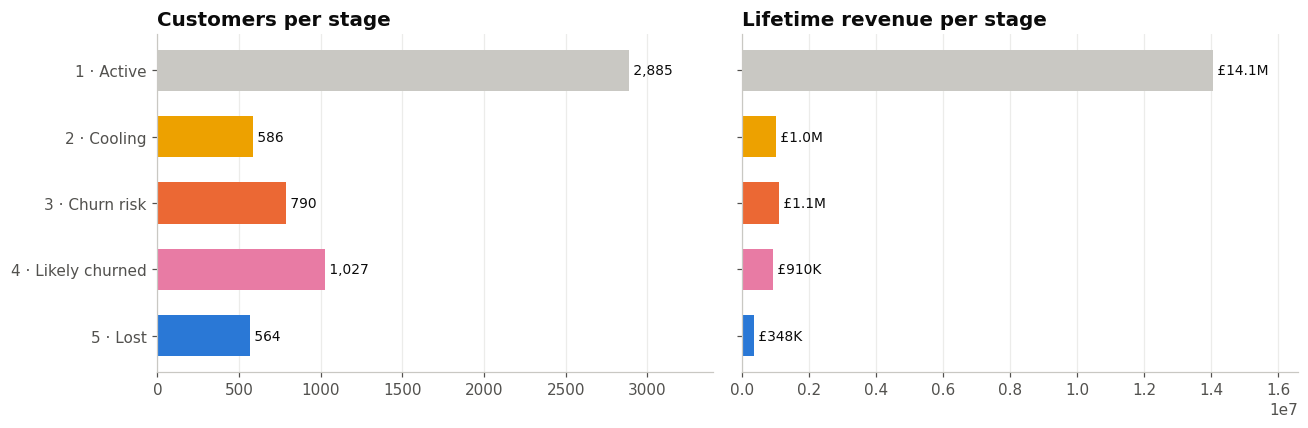

In [23]:
fig, (ax_count, ax_value) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
stage_colors = [GREY, YELLOW, ORANGE, MAGENTA, BLUE]
ypos = np.arange(len(stage_summary))[::-1]

for ax, column, title, fmt in [
    (ax_count, "customers",        "Customers per stage",        lambda v: f"{v:,.0f}"),
    (ax_value, "lifetime_revenue", "Lifetime revenue per stage", money),
]:
    ax.barh(ypos, stage_summary[column], color=stage_colors, height=0.62)
    for y, value in zip(ypos, stage_summary[column]):
        ax.text(value, y, " " + fmt(value), va="center", fontsize=9)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.18)

ax_count.set_yticks(ypos, stage_summary.index)
fig.tight_layout()
plt.show()

In [24]:
at_risk_vips_staged = rfm.loc[is_at_risk_vip].groupby("Stage", observed=True).agg(
    vips=("Monetary", "size"), lifetime_revenue=("Monetary", "sum")
)
at_risk_vips_staged.join(INCENTIVE_STAGES.set_index("stage")["incentive"])

,vips,lifetime_revenue,incentive
Stage,,,
3 · Churn risk,57,"487,061.57",10% discount on next order
4 · Likely churned,33,"276,326.55",15% discount + personalised picks
5 · Lost,9,"105,185.17",Win-back survey + 20% offer


## 10 · Key takeaways

In [25]:
champions = segment_summary.loc["Champions"]
at_risk = segment_summary.loc["At-Risk"]

print(f"""
1. CONCENTRATION  – The top {PARETO_TOP_SHARE:.0%} of customers generate {top_revenue_share:.0%} of revenue.
                    Losing a handful of big accounts hurts far more than losing many small ones.

2. CHAMPIONS      – {champions['customer_share']:.0%} of customers deliver {champions['revenue_share']:.0%} of revenue.
                    Protect them: early access, loyalty perks, no discounting needed.

3. AT-RISK        – {at_risk['customers']:,.0f} customers ({at_risk['revenue_share']:.0%} of revenue) used to buy often and went quiet.
                    {len(at_risk_vips):,} of them are VIPs worth £{at_risk_vips['Monetary'].sum():,.0f} – see outputs/at_risk_vips.csv.

4. INCENTIVES     – Scale the offer with time away: reminders at 3 months, 10% at 6, 15% at 12, 20% win-back after 18.

5. SEASONALITY    – Revenue peaks in Q4. Launch win-back campaigns in Sept/Oct so lapsed VIPs return for the peak.
""")


1. CONCENTRATION  – The top 20% of customers generate 77% of revenue.
                    Losing a handful of big accounts hurts far more than losing many small ones.

2. CHAMPIONS      – 25% of customers deliver 69% of revenue.
                    Protect them: early access, loyalty perks, no discounting needed.

3. AT-RISK        – 830 customers (9% of revenue) used to buy often and went quiet.
                    99 of them are VIPs worth £868,573 – see outputs/at_risk_vips.csv.

4. INCENTIVES     – Scale the offer with time away: reminders at 3 months, 10% at 6, 15% at 12, 20% win-back after 18.

5. SEASONALITY    – Revenue peaks in Q4. Launch win-back campaigns in Sept/Oct so lapsed VIPs return for the peak.

